<a href="https://colab.research.google.com/github/saopa28/INSE-6450/blob/main/INSE6450.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Environment Setup

## Dependencies

In [ ]:
!pip install pandas scikit-learn

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1


## Clone Github

In [ ]:
!git clone https://github.com/saopa28/INSE-6450.git

Cloning into 'INSE-6450'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 34 (delta 5), reused 31 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (34/34), 8.42 MiB | 11.71 MiB/s, done.
Resolving deltas: 100% (5/5), done.


In [ ]:
print("\nFetching latest updates from GitHub...")
%cd /content/INSE-6450
!git pull origin main


Fetching latest updates from GitHub...
/content/INSE-6450
From https://github.com/saopa28/INSE-6450
 * branch            main       -> FETCH_HEAD
Already up to date.


## Dataset form Hugging Face

In [ ]:
import pandas as pd

df = pd.read_csv("hf://datasets/criteo/criteo-uplift/criteo-research-uplift-v2.1.csv.gz")

# Exploratory Data Analysis (EDA)

1. General Data analysis for shape, values and data types

In [ ]:
print("SHAPE:", df.shape)

print("\nFIRST 5 ROWS:")
display(df.head())

print("\nDATA TYPES:")
df.info()

SHAPE: (13979592, 16)

FIRST 5 ROWS:


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0



DATA TYPES:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13979592 entries, 0 to 13979591
Data columns (total 16 columns):
 #   Column      Dtype  
---  ------      -----  
 0   f0          float64
 1   f1          float64
 2   f2          float64
 3   f3          float64
 4   f4          float64
 5   f5          float64
 6   f6          float64
 7   f7          float64
 8   f8          float64
 9   f9          float64
 10  f10         float64
 11  f11         float64
 12  treatment   int64  
 13  conversion  int64  
 14  visit       int64  
 15  exposure    int64  
dtypes: float64(12), int64(4)
memory usage: 1.7 GB


2. Missingness report + summary stats for numeric fields

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})

display(missing_summary.sort_values("Missing (%)", ascending=False))

print("\nSTATS:")
df.describe(include="all")

,Missing Count,Missing (%)
f0,0,0.0
f1,0,0.0
f2,0,0.0
f3,0,0.0
f4,0,0.0
f5,0,0.0
f6,0,0.0
f7,0,0.0
f8,0,0.0
f9,0,0.0



STATS:


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
count,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07
mean,1.962030e+01,1.006998e+01,8.446582e+00,4.178923e+00,1.033884e+01,4.028513e+00,-4.155356e+00,5.101765e+00,3.933581e+00,1.602764e+01,5.333396e+00,-1.709672e-01,8.500001e-01,2.916680e-03,4.699200e-02,3.063122e-02
std,5.377464e+00,1.047557e-01,2.993161e-01,1.336645e+00,3.433081e-01,4.310974e-01,4.577914e+00,1.205248e+00,5.665958e-02,7.018975e+00,1.682288e-01,2.283277e-02,3.570713e-01,5.392748e-02,2.116217e-01,1.723164e-01
min,1.261636e+01,1.005965e+01,8.214383e+00,-8.398387e+00,1.028053e+01,-9.011892e+00,-3.142978e+01,4.833815e+00,3.635107e+00,1.319006e+01,5.300375e+00,-1.383941e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.261636e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-6.699321e+00,4.833815e+00,3.910792e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.192341e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-2.411115e+00,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2.443646e+01,1.005965e+01,8.723335e+00,4.679882e+00,1.028053e+01,4.115453e+00,2.944427e-01,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,2.674526e+01,1.634419e+01,9.051962e+00,4.679882e+00,2.112351e+01,4.115453e+00,2.944427e-01,1.199840e+01,3.971858e+00,7.529502e+01,6.473917e+00,-1.686792e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


3. Checking for duplicates for each feature

In [ ]:
duplicate_summary = pd.DataFrame({
    "Duplicate Count": [
        df[col].duplicated().sum() for col in df.columns
    ],
    "Unique Values": [
        df[col].nunique() for col in df.columns
    ]
}, index=df.columns)

display(duplicate_summary)

,Duplicate Count,Unique Values
f0,11797633,2181959
f1,13979532,60
f2,11927692,2051900
f3,13979040,552
f4,13979332,260
f5,13979460,132
f6,13977947,1645
f7,13357449,622143
f8,13975849,3743
f9,13977998,1594


In [ ]:
duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df)) * 100

print(f"Duplicate rows: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate rows: 1259545
Duplicate percentage: 9.01%


In [ ]:
X = df.drop(columns=["exposure"])

print("Duplicate feature rows:", X.duplicated().sum())

Duplicate feature rows: 1266415


4. Do duplicate rows have the same labels or different labels?

In [ ]:
features = [f"f{i}" for i in range(12)]

conflicts = (
    df.groupby(features + ["treatment"], dropna=False)
    [["conversion", "visit"]]
    .nunique(dropna=False)
)

print(
    "Feature combinations with varying conversion:",
    (conflicts["conversion"] > 1).sum()
)

print(
    "Feature combinations with varying visits:",
    (conflicts["visit"] > 1).sum()
)

Feature combinations with varying conversion: 212
Feature combinations with varying visits: 3834


5. What is the feature distribution of the control group?

In [ ]:
control_df = df[df["treatment"]==0]
features = [f"f{i}" for i in range(12)]
control_features = control_df[features]

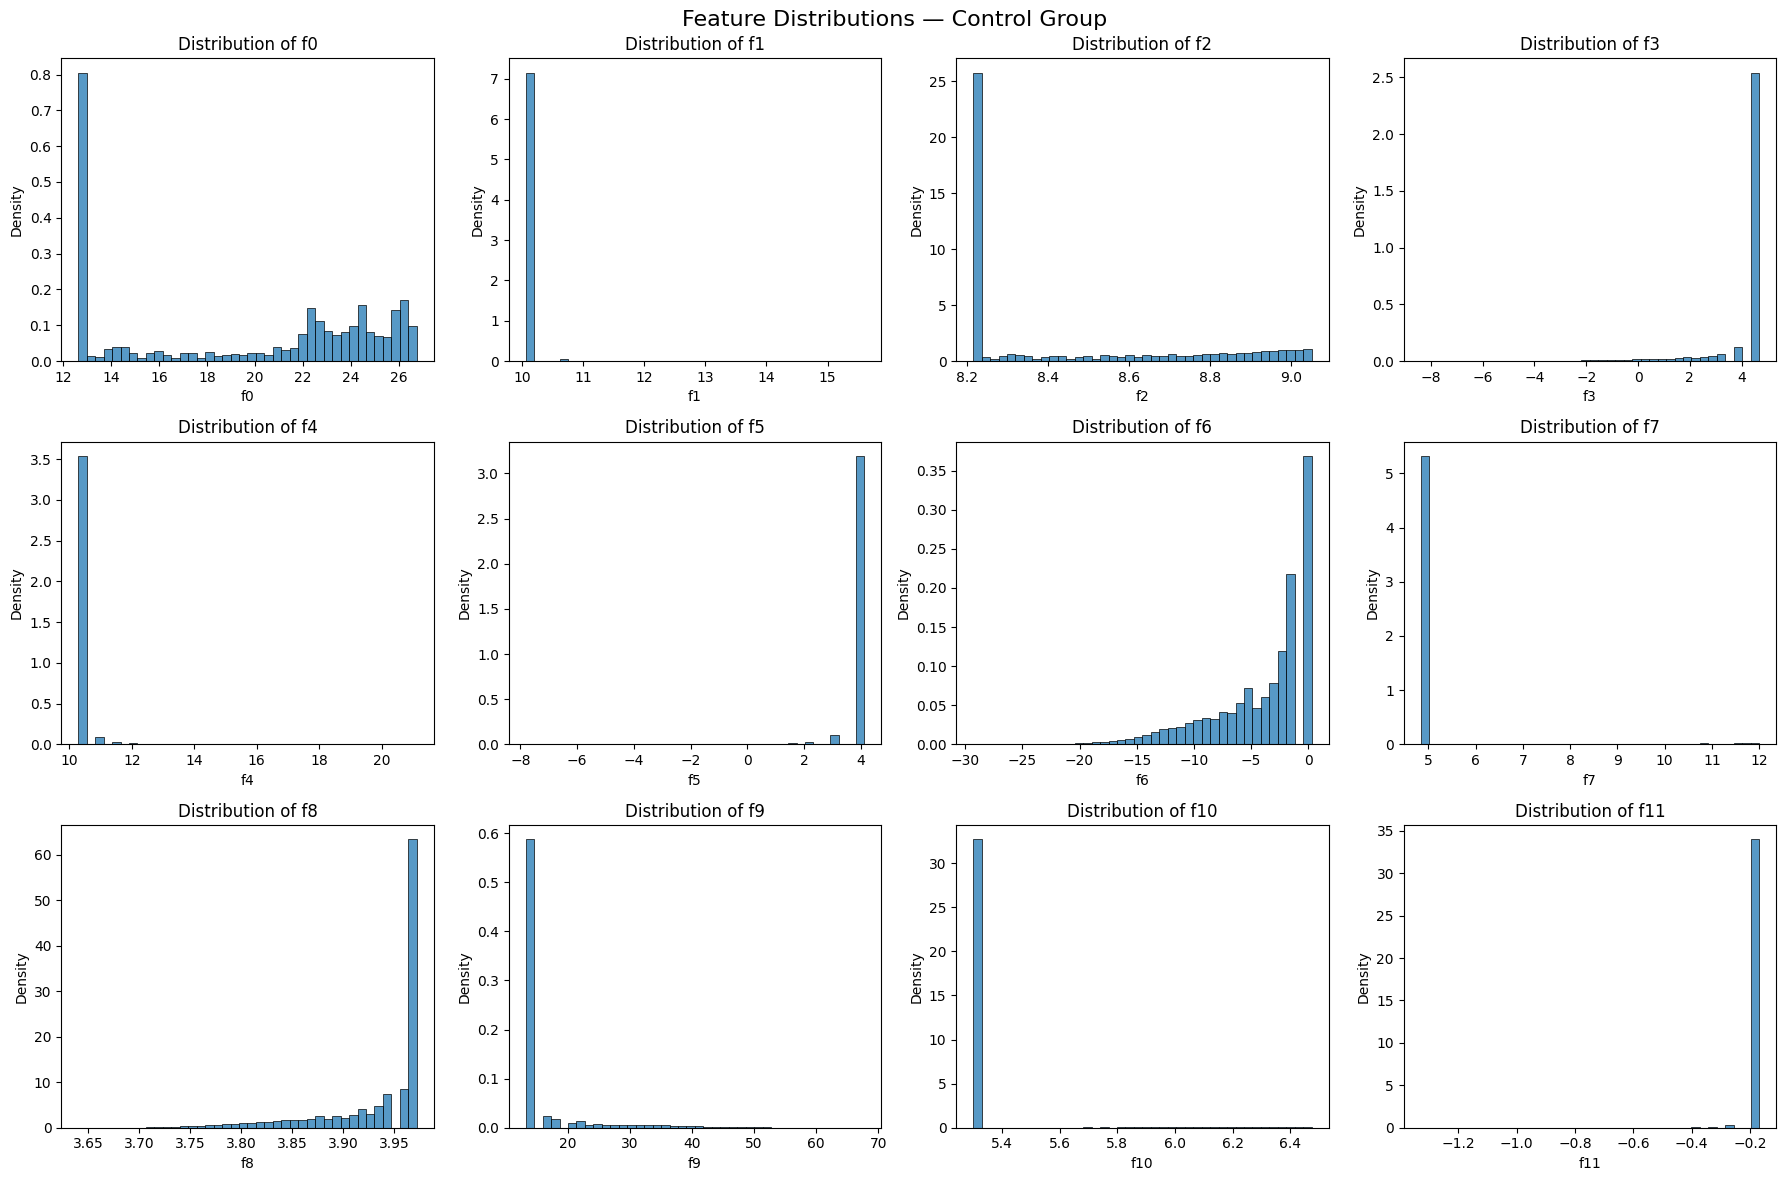

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for i, col in enumerate(features):
    ax = axes.flat[i]

    sns.histplot(
        data=control_features,
        x=col,
        bins=40,
        kde=False,
        stat="density",
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

plt.suptitle("Feature Distributions — Control Group", fontsize=16)
plt.tight_layout()
plt.show()

6. What is the feature distribution of the treatment group?

In [ ]:
treatment_df = df[df["treatment"]==1]
features = [f"f{i}" for i in range(12)]
treatment_features = treatment_df[features]

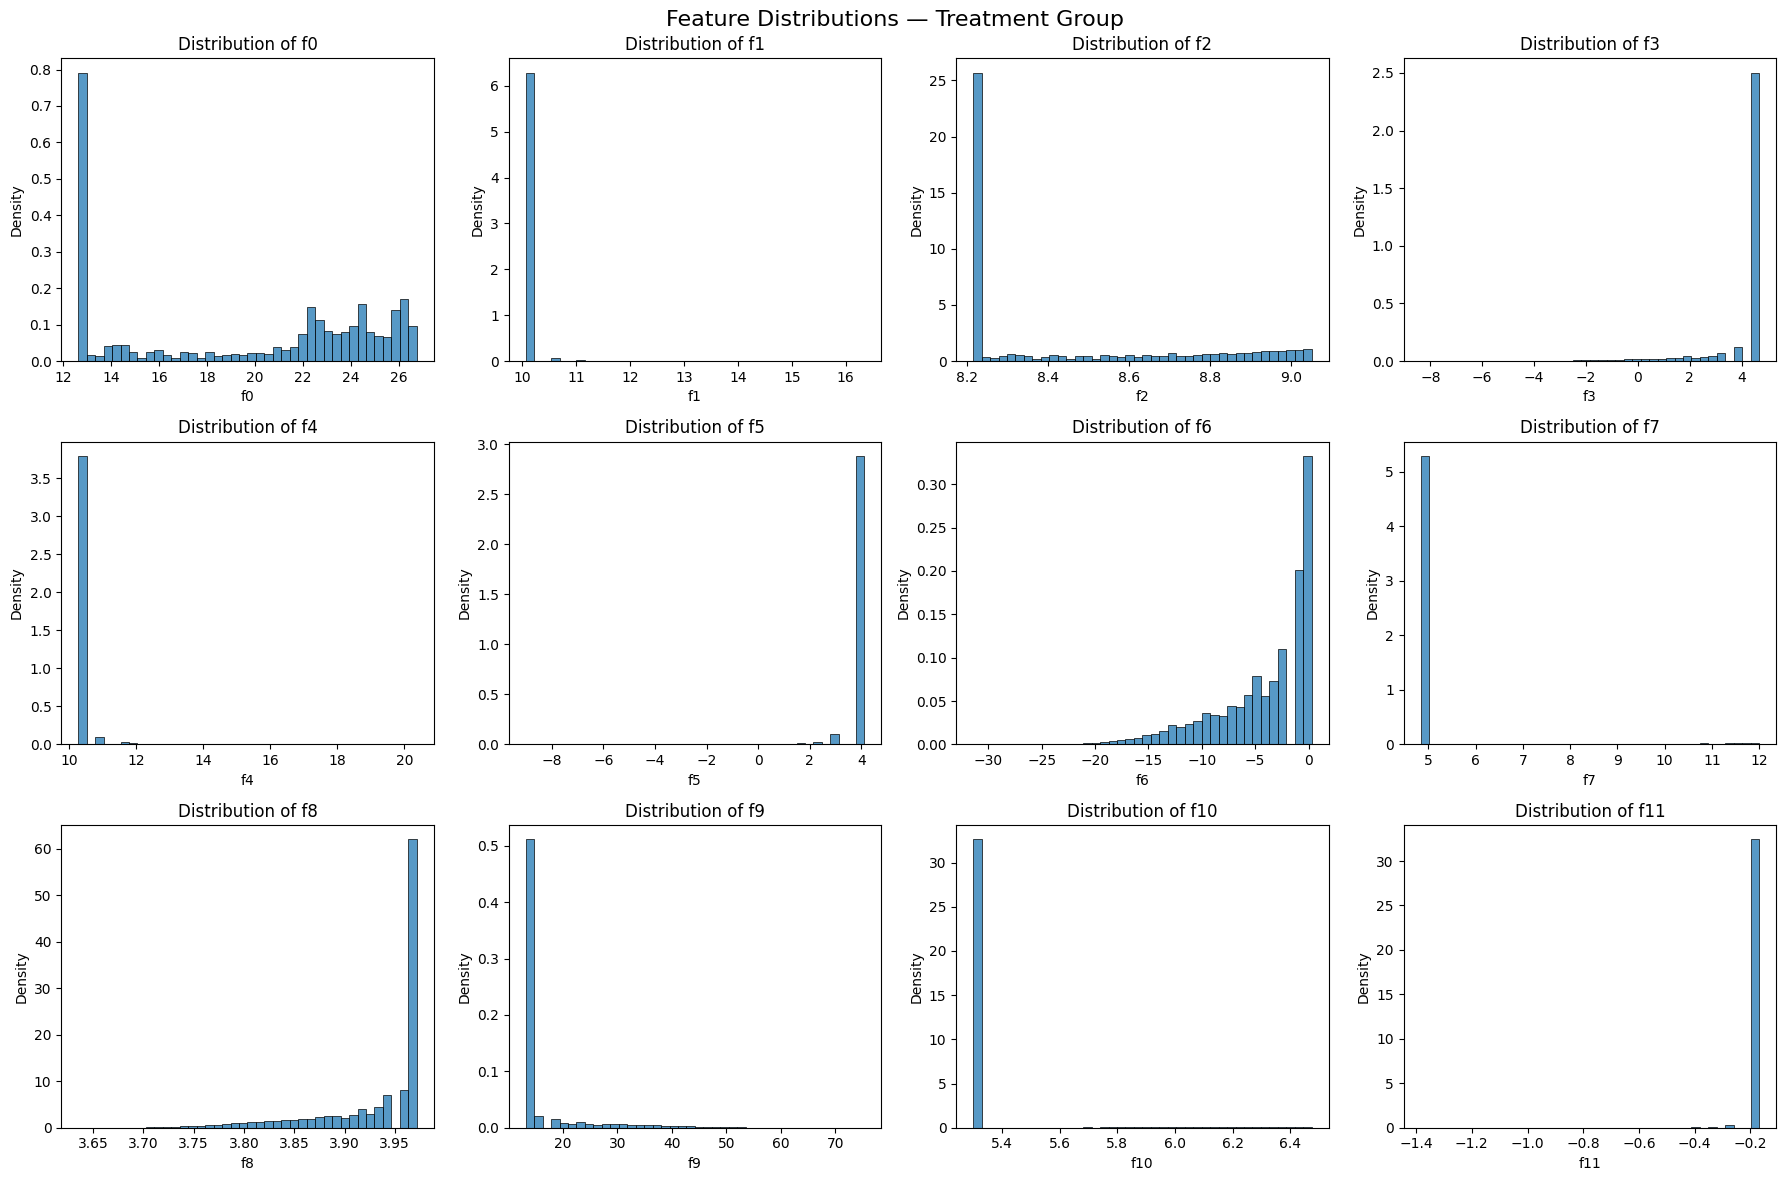

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for i, col in enumerate(features):
    ax = axes.flat[i]

    sns.histplot(
        data=treatment_features,
        x=col,
        bins=40,
        kde=False,
        stat="density",
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

plt.suptitle("Feature Distributions — Treatment Group", fontsize=16)
plt.tight_layout()
plt.show()

7. What features are most strongly associated with  conversion vs. visit in the treatment group?

In [ ]:
correlation = treatment_df[
    features + ["exposure","conversion", "visit"]
].corr()

feature_corr = correlation.loc[
    features, ["exposure","conversion", "visit"]
]

display(feature_corr)

,exposure,conversion,visit
f0,-0.133971,-0.039300,-0.137030
f1,0.200443,0.083971,0.117078
f2,0.005393,-0.014469,-0.030167
f3,-0.397951,-0.107412,-0.218705
f4,0.170094,0.301748,0.268308
f5,-0.243926,-0.088510,-0.144930
f6,-0.289447,-0.074706,-0.147008
f7,0.161374,0.045396,0.096730
f8,-0.219863,-0.133612,-0.462612
f9,0.223140,0.159482,0.499208


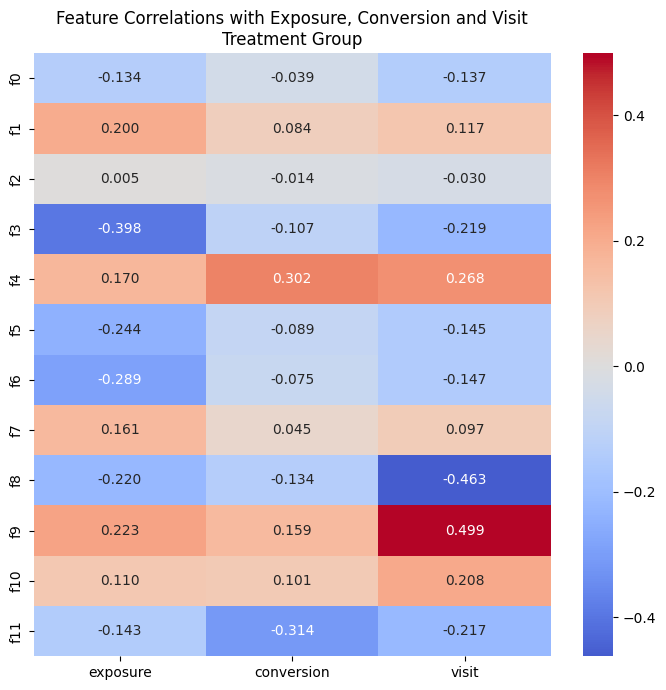

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 7))

sns.heatmap(
    feature_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".3f"
)

plt.title("Feature Correlations with Exposure, Conversion and Visit\nTreatment Group")
plt.tight_layout()
plt.show()

In [ ]:
ranked_corr = feature_corr.abs().sort_values(
    "conversion",
    ascending=False
)

display(ranked_corr)

,exposure,conversion,visit
f11,0.142552,0.313971,0.216863
f4,0.170094,0.301748,0.268308
f9,0.223140,0.159482,0.499208
f8,0.219863,0.133612,0.462612
f3,0.397951,0.107412,0.218705
f10,0.109699,0.101206,0.207781
f5,0.243926,0.088510,0.144930
f1,0.200443,0.083971,0.117078
f6,0.289447,0.074706,0.147008
f7,0.161374,0.045396,0.096730


8. Probability of conversion vs visit in the treament group after exposure and probability of conversion vs visit in control.

In [ ]:
#Group that is under treatment and was exposed
treated_and_exposed = df [
    (df["treatment"]==1)&
    (df["exposure"]==1)
]

In [ ]:
import pandas as pd

probabilities = pd.DataFrame({
    "Treated & Exposed": [
        treated_and_exposed["conversion"].mean(),
        treated_and_exposed["visit"].mean()
    ],
    "Control": [
        control_df["conversion"].mean(),
        control_df["visit"].mean()
    ]
}, index=["Conversion", "Visit"])

display(probabilities)

,Treated & Exposed,Control
Conversion,0.053784,0.001938
Visit,0.414538,0.038201


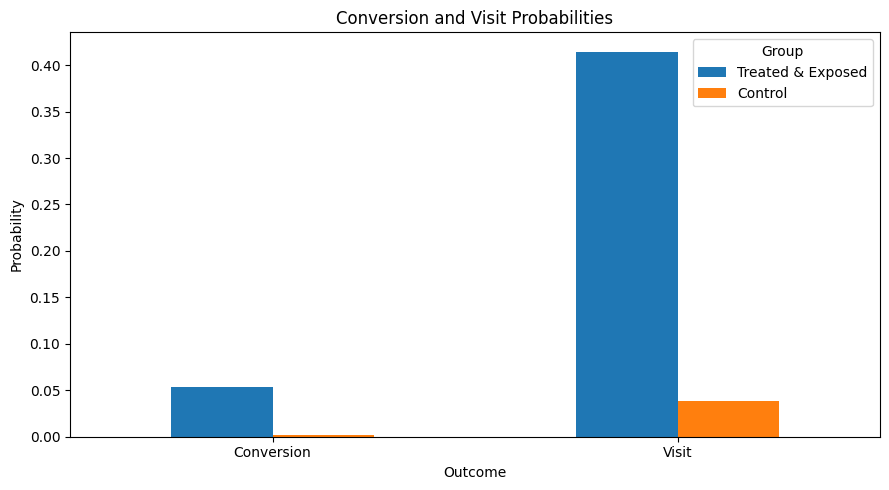

In [ ]:
ax = probabilities.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Conversion and Visit Probabilities")
plt.ylabel("Probability")
plt.xlabel("Outcome")
plt.legend(
    ["Treated & Exposed", "Control"],
    title="Group"
)
plt.tight_layout()
plt.show()

9. Outliers in the data for control group and treatment group

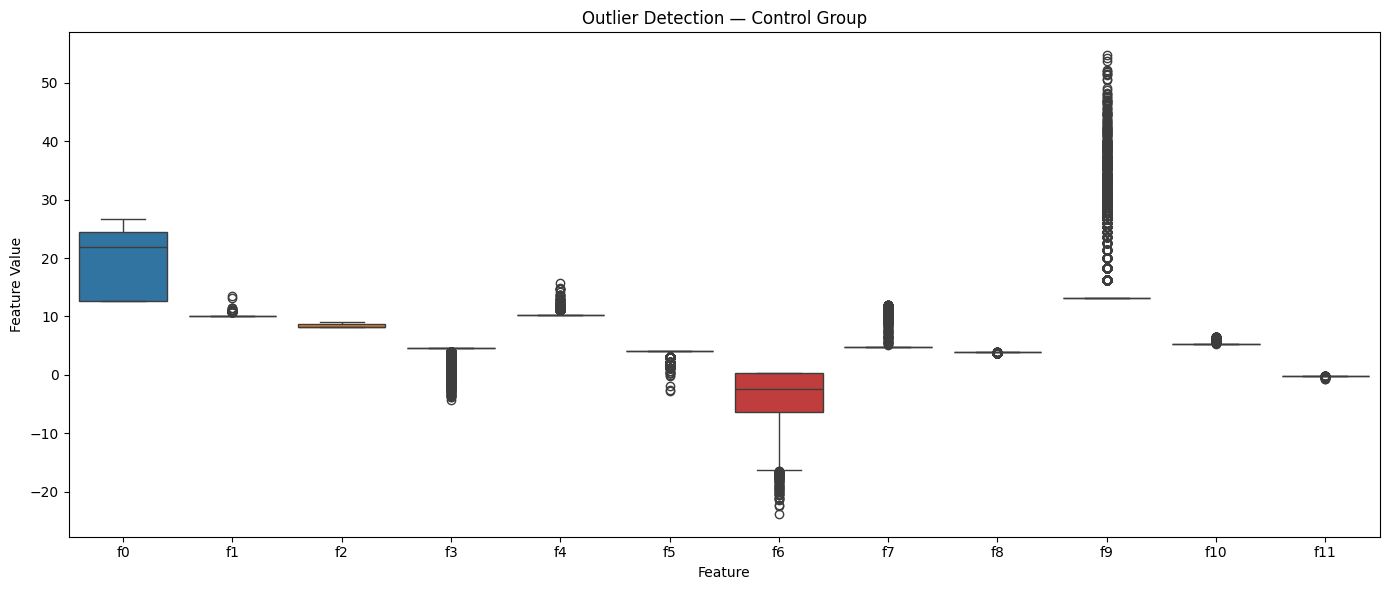

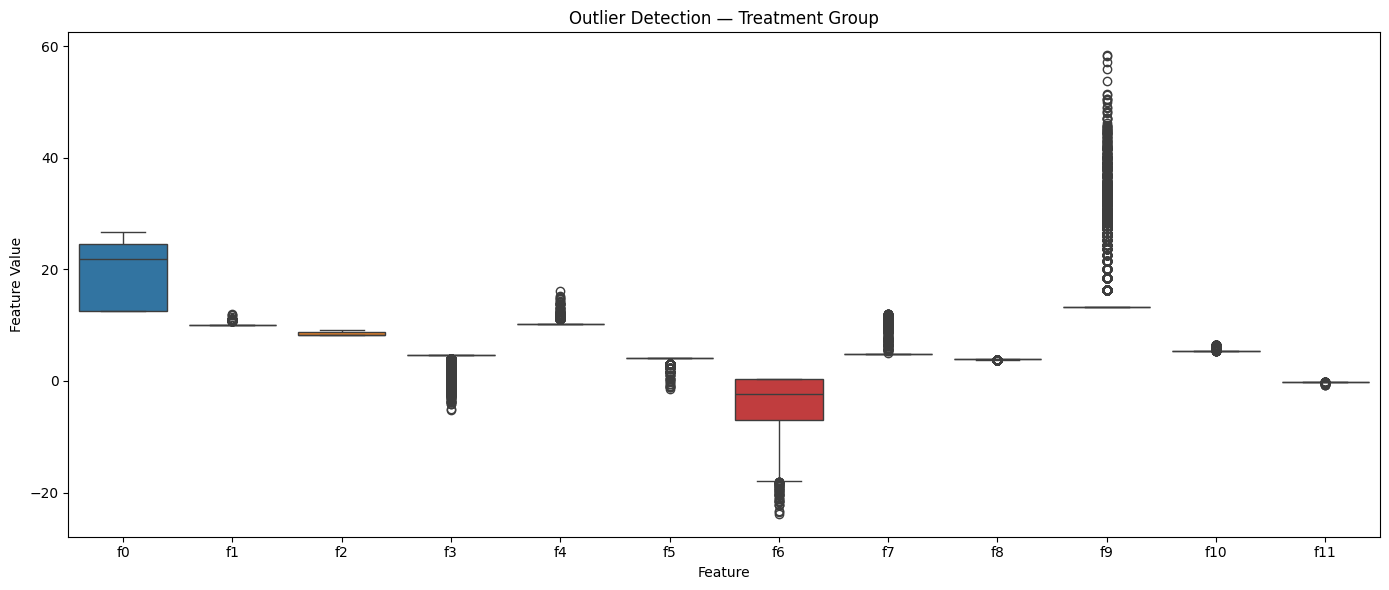

In [ ]:
# Sample for visualization
control_sample = control_df.sample(
    n=min(5000, len(control_df)),
    random_state=42
)

treatment_sample = treatment_df.sample(
    n=min(5000, len(treatment_df)),
    random_state=42
)

# Consistent feature colours
palette = dict(zip(features, sns.color_palette("tab20", 12)))

for group_name, group_df in [
    ("Control Group", control_sample),
    ("Treatment Group", treatment_sample)
]:
    long_df = group_df[features].melt(
        var_name="Feature",
        value_name="Value"
    )

    plt.figure(figsize=(14, 6))

    sns.boxplot(
        data=long_df,
        x="Feature",
        y="Value",
        hue="Feature",
        palette=palette,
        dodge=False,
        legend=False,
        showfliers=True
    )

    plt.title(f"Outlier Detection — {group_name}")
    plt.xlabel("Feature")
    plt.ylabel("Feature Value")
    plt.tight_layout()
    plt.show()

10. Class- Is it balanced or Imbalanced?

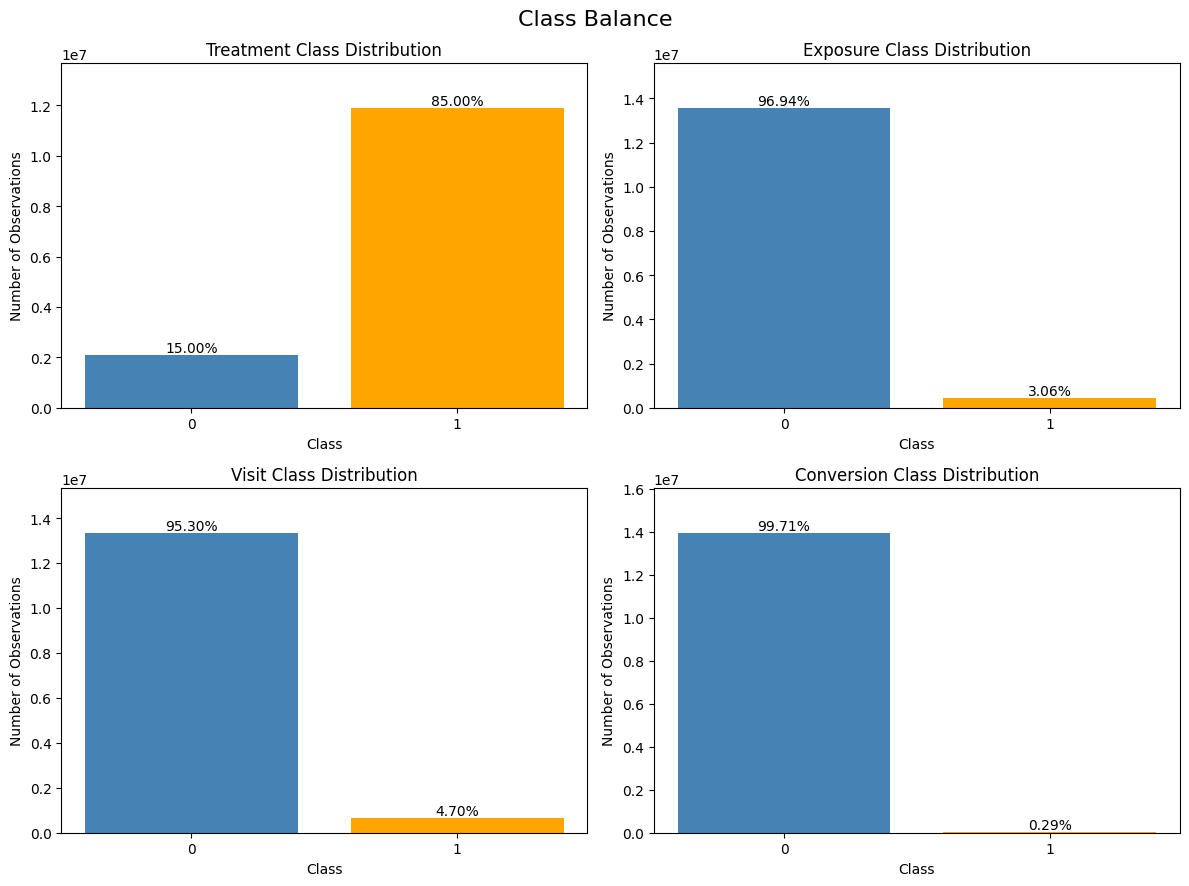

In [ ]:
labels = ["treatment", "exposure", "visit", "conversion"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, col in zip(axes.flat, labels):
    counts = df[col].value_counts().reindex([0, 1], fill_value=0)
    percentages = counts / counts.sum() * 100

    bars = ax.bar(
        ["0", "1"],
        counts.values,
        color=["steelblue", "orange"]
    )

    for bar, pct in zip(bars, percentages):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{pct:.2f}%",
            ha="center",
            va="bottom"
        )

    ax.set_title(f"{col.capitalize()} Class Distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of Observations")
    ax.set_ylim(0, counts.max() * 1.15 if counts.max() else 1)

plt.suptitle("Class Balance", fontsize=16)
plt.tight_layout()
plt.show()

11. Label Noise

In [ ]:
labels = ["treatment", "exposure", "visit", "conversion"]

label_combinations = (
    df.groupby(labels, dropna=False)
    .size()
    .reset_index(name="Count")
)

label_combinations["Percentage"] = (
    label_combinations["Count"] / len(df) * 100
).round(2)

display(
    label_combinations.sort_values("Count", ascending=False)
)

,treatment,exposure,visit,conversion,Count,Percentage
3,1,0,0,0,11055129,79.08
0,0,0,0,0,2016832,14.43
4,1,0,1,0,385634,2.76
6,1,1,0,0,250702,1.79
7,1,1,1,0,154479,1.11
1,0,0,1,0,76042,0.54
8,1,1,1,1,23031,0.16
5,1,0,1,1,13680,0.10
2,0,0,1,1,4063,0.03


In [ ]:
invalid_exposure = df[
    (df["treatment"] == 0) &
    (df["exposure"] == 1)
]

print("Control users marked as exposed:", len(invalid_exposure))

Control users marked as exposed: 0


# Feature Engineering

Checking to see if candidate features are correlated to conversion, visit, and exposure

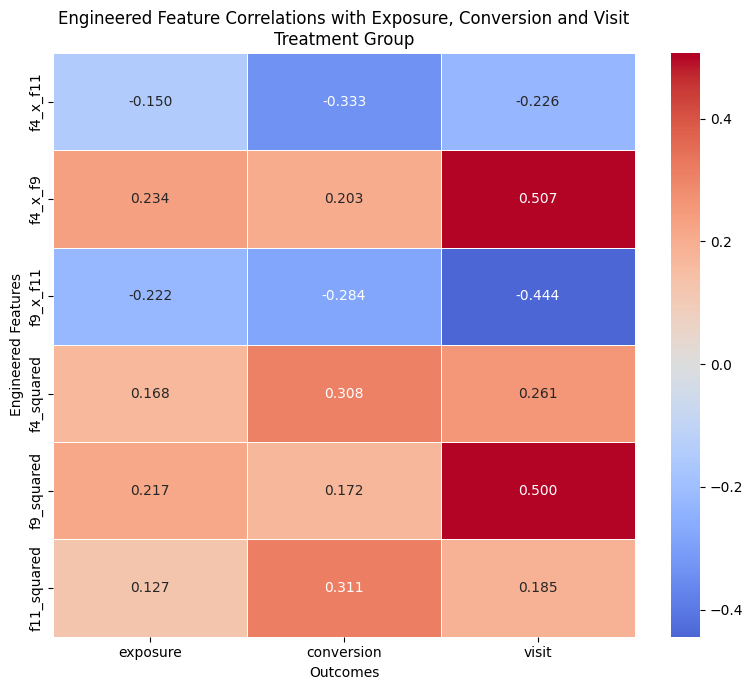

In [ ]:
treatment_df = df[df["treatment"] == 1].copy()

treatment_df["f4_x_f11"] = treatment_df["f4"] * treatment_df["f11"]
treatment_df["f4_x_f9"] = treatment_df["f4"] * treatment_df["f9"]
treatment_df["f9_x_f11"] = treatment_df["f9"] * treatment_df["f11"]

treatment_df["f4_squared"] = treatment_df["f4"] ** 2
treatment_df["f9_squared"] = treatment_df["f9"] ** 2
treatment_df["f11_squared"] = treatment_df["f11"] ** 2

engineered_features = [
    "f4_x_f11",
    "f4_x_f9",
    "f9_x_f11",
    "f4_squared",
    "f9_squared",
    "f11_squared"
]

outcomes = ["exposure", "conversion", "visit"]

feature_corr = treatment_df[
    engineered_features + outcomes
].corr().loc[engineered_features, outcomes]


plt.figure(figsize=(8, 7))

sns.heatmap(
    feature_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".3f",
    linewidths=0.5
)

plt.title(
    "Engineered Feature Correlations with Exposure, Conversion and Visit\n"
    "Treatment Group"
)

plt.xlabel("Outcomes")
plt.ylabel("Engineered Features")

plt.tight_layout()
plt.show()

# Output Artifact

Creating the engineered features

In [7]:
# Interaction features
df["f4_x_f11"] = df["f4"] * df["f11"]
df["f4_x_f9"] = df["f4"] * df["f9"]
df["f9_x_f11"] = df["f9"] * df["f11"]

# Polynomial features
df["f4_squared"] = df["f4"] ** 2
df["f9_squared"] = df["f9"] ** 2
df["f11_squared"] = df["f11"] ** 2

# Verify dataset
assert df.shape == (13_979_592, 22)

print("Engineered dataset shape:", df.shape)
print("\nEngineered columns:")
print(df.columns.tolist())

display(df.head())


Engineered dataset shape: (13979592, 22)

Engineered columns:
['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure', 'f4_x_f11', 'f4_x_f9', 'f9_x_f11', 'f4_squared', 'f9_squared', 'f11_squared']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,...,treatment,conversion,visit,exposure,f4_x_f11,f4_x_f9,f9_x_f11,f4_squared,f9_squared,f11_squared
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,...,1,0,0,0,-1.734111,135.600703,-2.224888,105.689199,173.977576,0.028453
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,...,1,0,0,0,-1.734111,135.600703,-2.224888,105.689199,173.977576,0.028453
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,...,1,0,0,0,-1.734111,135.600703,-2.224888,105.689199,173.977576,0.028453
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,...,1,0,0,0,-1.734111,135.600703,-2.224888,105.689199,173.977576,0.028453
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,...,1,0,0,0,-1.734111,135.600703,-2.224888,105.689199,173.977576,0.028453


In [ ]:
import zipfile
import io
import os

zip_filename = "criteo_uplift_engineered.zip"
csv_filename = "criteo_uplift_engineered.csv"

with zipfile.ZipFile(
    zip_filename,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
    allowZip64=True
) as zip_file:

    with zip_file.open(csv_filename, "w", force_zip64=True) as binary_file:
        with io.TextIOWrapper(
            binary_file, encoding="utf-8", newline=""
        ) as text_file:
            df.to_csv(text_file, index=False)

zip_size_gb = os.path.getsize(zip_filename) / (1024 ** 3)

print("ZIP created successfully.")
print(f"Filename: {zip_filename}")
print(f"Size: {zip_size_gb:.2f} GiB")
print(f"Number of rows: {len(df):,}")
print(f"Number of columns: {len(df.columns)}")


Saving the Output Artifact to Github

In [ ]:

import shutil
import subprocess
from google.colab import userdata

repo = "saopa28/INSE-6450"

secret_name = "GITHUB_TOKEN"

zip_filename = "criteo_uplift_engineered.zip"
release_tag = "v1.0-engineered"

if not os.path.isfile(zip_filename):
    raise FileNotFoundError(f"File not found: {zip_filename}")

if shutil.which("gh") is None:
    raise RuntimeError(
        "GitHub CLI is not installed. Run: !apt-get install -y gh"
    )

size_mb = os.path.getsize(zip_filename) / (1024 ** 2)
print(f"ZIP size: {size_mb:.2f} MiB")

if size_mb >= 2048:
    raise ValueError("ZIP exceeds GitHub's 2 GiB release asset limit.")


token = userdata.get(secret_name)

if not token:
    raise ValueError("GitHub token not found in Colab Secrets.")

env = os.environ.copy()
env["GH_TOKEN"] = token

# ===== UPLOAD TO GITHUB RELEASES =====
try:
    result = subprocess.run(
        [
            "gh", "release", "create",
            release_tag,
            zip_filename,
            "--repo", repo,
            "--target", "main",
            "--title", "Criteo Uplift Engineered Dataset v1.0",
            "--notes",
            "Criteo Uplift Dataset v2.1 containing "
            "13,979,592 observations and 22 columns, "
            "including six engineered interaction "
            "and polynomial features."
        ],
        env=env,
        text=True,
        capture_output=True,
        check=True
    )

    print("Upload successful!")
    print(result.stdout)

    print("\nView your release:")
    print(
        f"https://github.com/{repo}/releases/tag/{release_tag}"
    )

finally:
    env.pop("GH_TOKEN", None)
    del token
